In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Prepare the dataset
# Input feature: hours studied
X = np.array([[1], [2], [3], [4], [5],
              [6], [7], [8], [9], [10],
             [5.5], [6.5], [5.4],[3.4]])

# Target: 0 = Fail, 1 = Pass
y = np.array([0, 0, 0, 1, 0, 1, 1, 0, 1, 1,1,1,0,0])


In [3]:
# 2. Create the Logistic Regression model
model = LogisticRegression()

# 3. Train the model
model.fit(X, y)

# 4. Make predictions
y_pred = model.predict(X)

# 5. Display the results
print("Actual values:    ", y)
print("Predicted values: ", y_pred)

Actual values:     [0 0 0 1 0 1 1 0 1 1 1 1 0 0]
Predicted values:  [0 0 0 0 0 1 1 1 1 1 1 1 1 0]


In [4]:
# 6. Evaluate the model
accuracy = accuracy_score(y, y_pred)
print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y, y_pred))

print("\nClassification Report:")
print(classification_report(y, y_pred, zero_division=0))


Accuracy: 0.7857142857142857

Confusion Matrix:
[[5 2]
 [1 6]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.71      0.77         7
           1       0.75      0.86      0.80         7

    accuracy                           0.79        14
   macro avg       0.79      0.79      0.78        14
weighted avg       0.79      0.79      0.78        14



Hours: 4.5, Prediction: Fail, Pass probability: 0.37
Hours: 6.5, Prediction: Pass, Pass probability: 0.65
Hours: 8.5, Prediction: Pass, Pass probability: 0.86


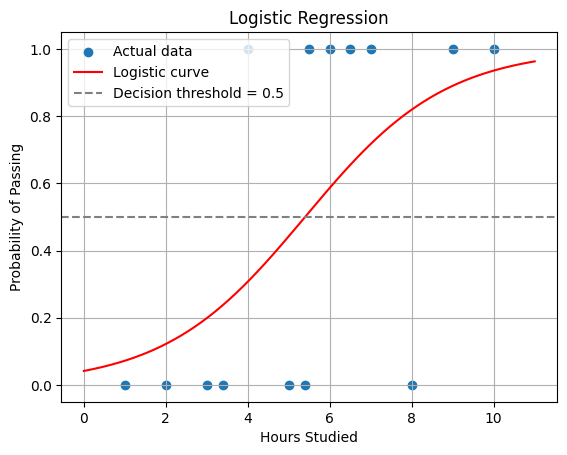

In [5]:
# 7. Predict for a new student
hours = np.array([[4.5], [6.5], [8.5]])

predictions = model.predict(hours)
probabilities = model.predict_proba(hours)

for i in range(len(hours)):
    result = "Pass" if predictions[i] == 1 else "Fail"
    print(
        f"Hours: {hours[i][0]}, "
        f"Prediction: {result}, "
        f"Pass probability: {probabilities[i][1]:.2f}"
    )

# 8. Plot the data and predicted probabilities
x_plot = np.linspace(0, 11, 200).reshape(-1, 1)
y_prob = model.predict_proba(x_plot)[:, 1]

plt.scatter(X, y, label="Actual data")
plt.plot(x_plot, y_prob, color="red", label="Logistic curve")
plt.axhline(y=0.5, linestyle="--", color="gray",
            label="Decision threshold = 0.5")

plt.xlabel("Hours Studied")
plt.ylabel("Probability of Passing")
plt.title("Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()
